# 06 · Mô hình gợi ý: biểu đồ đánh giá

Notebook này **không chạy Spark**. Nó đọc số liệu bước 06 đã ghi ra máy:
`data/output/models_metrics.json` (bảng xếp hạng chung + khoảng tin cậy) và `data/output/model_*_report.json`
(06a chia dữ liệu, 06b ALS, 06c content, 06d FP-Growth, 06e K-means, 06f hybrid, 06g đối chứng),
rồi lưu PNG vào `docs/images/nb_06_*.png`.

> Dữ liệu hành vi là **mô phỏng**. Đánh giá trên tháng test 09/2026 (39.012 user), dò tham số trên tháng val 08/2026.

Chạy lại: `docker exec -w /home/jovyan/work/notebooks jupyter jupyter nbconvert --to notebook --execute --inplace 06_mo_hinh.ipynb`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nb_style import C, SERIES, SEQ, load, save, fmt, bar_labels

mm = load("models_metrics.json")
R = pd.DataFrame(mm["ranking"])
als, cont, hyb = load("model_als_report.json"), load("model_content_report.json"), load("model_hybrid_report.json")
km, fp, ctl = load("model_kmeans_report.json"), load("model_fpgrowth_report.json"), load("model_control_report.json")
NAME = {"random": "Ngẫu nhiên", "pop_chung": "Phổ biến chung", "pop_gan_day": "Phổ biến 2 tháng cuối",
        "pop_vung_tuoi": "Phổ biến theo vùng–tuổi", "content": "Content (TF-IDF)", "nau_lai": "Nấu lại",
        "als_implicit": "ALS implicit", "hybrid": "Hybrid", "hybrid_c2": "Hybrid + content 2 vị trí"}
print(mm["note"])

Dữ liệu hành vi MÔ PHỎNG. Mọi mô hình xếp hạng chấm trên cùng tập user (D12).


## 1. Bảng so sánh mô hình (test, top 10, mọi user được đánh giá)

In [2]:
main = R[(R.view == "test") & (R.variant == "chính") & (R.group == "tất cả")].set_index("model")
beyond = R[(R.view == "test") & (R.variant == "ngoài độ chính xác") & (R.group == "tất cả")].set_index("model")
explore = R[(R.view == "test") & (R.variant == "khám phá") & (R.group == "tất cả")].set_index("model")
tbl = pd.DataFrame({
    "Mô hình": [NAME[m] for m in main.index],
    "P@10": main["p@10"], "R@10": main["r@10"], "NDCG@10": main["ndcg@10"], "MAP@10": main["ap@10"],
    "Coverage %": beyond.reindex(main.index)["coverage_pct"], "Novelty": beyond.reindex(main.index)["novelty"],
    "Diversity": beyond.reindex(main.index)["diversity"], "NDCG@10 khám phá": explore.reindex(main.index)["ndcg@10"],
}).sort_values("NDCG@10", ascending=False)
tbl.round(4)

,Mô hình,P@10,R@10,NDCG@10,MAP@10,Coverage %,Novelty,Diversity,NDCG@10 khám phá
model,,,,,,,,,
hybrid,Hybrid,0.0838,0.1786,0.1588,0.0906,41.30,9.127,0.8544,0.0960
als_implicit,ALS implicit,0.0813,0.1725,0.1539,0.0877,40.48,9.285,0.8483,0.0956
hybrid_c2,Hybrid + content 2 vị trí,0.0744,0.1599,0.1495,0.0869,57.97,9.910,0.8494,0.0846
nau_lai,Nấu lại,0.0691,0.1417,0.1317,0.0746,97.55,10.261,0.8948,0.0263
pop_vung_tuoi,Phổ biến theo vùng–tuổi,0.0324,0.0655,0.0571,0.0283,0.47,7.511,0.9092,0.0314
pop_chung,Phổ biến chung,0.0286,0.0583,0.0510,0.0251,0.18,7.317,0.9172,0.0281
pop_gan_day,Phổ biến 2 tháng cuối,0.0282,0.0555,0.0497,0.0244,0.18,7.382,0.9138,0.0275
content,Content (TF-IDF),0.0065,0.0117,0.0095,0.0039,77.01,12.926,0.7360,0.0087
random,Ngẫu nhiên,0.0010,0.0019,0.0015,0.0006,100.00,13.897,0.9424,0.0012


da ghi docs/images/nb_06_ndcg_mo_hinh.png


'/home/jovyan/work/docs/images/nb_06_ndcg_mo_hinh.png'

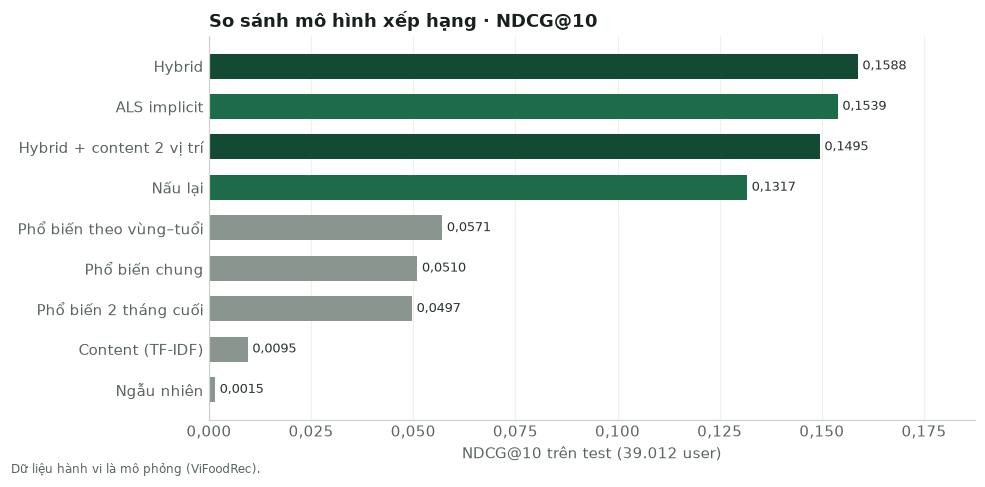

In [3]:
t = tbl.sort_values("NDCG@10")
fig, ax = plt.subplots(figsize=(9, 4.4))
colors = [C["herb_dark"] if m.startswith("Hybrid") else (C["herb"] if m in ("ALS implicit", "Nấu lại") else C["neutral"])
          for m in t["Mô hình"]]
b = ax.barh(t["Mô hình"], t["NDCG@10"], color=colors, height=0.62)
bar_labels(ax, b, nd=4, horizontal=True)
ax.set_xlim(0, t["NDCG@10"].max() * 1.18)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("NDCG@10 trên test (39.012 user)")
ax.set_title("So sánh mô hình xếp hạng · NDCG@10")
fig.tight_layout()
save(fig, "06_ndcg_mo_hinh")

da ghi docs/images/nb_06_bang_so_sanh.png


'/home/jovyan/work/docs/images/nb_06_bang_so_sanh.png'

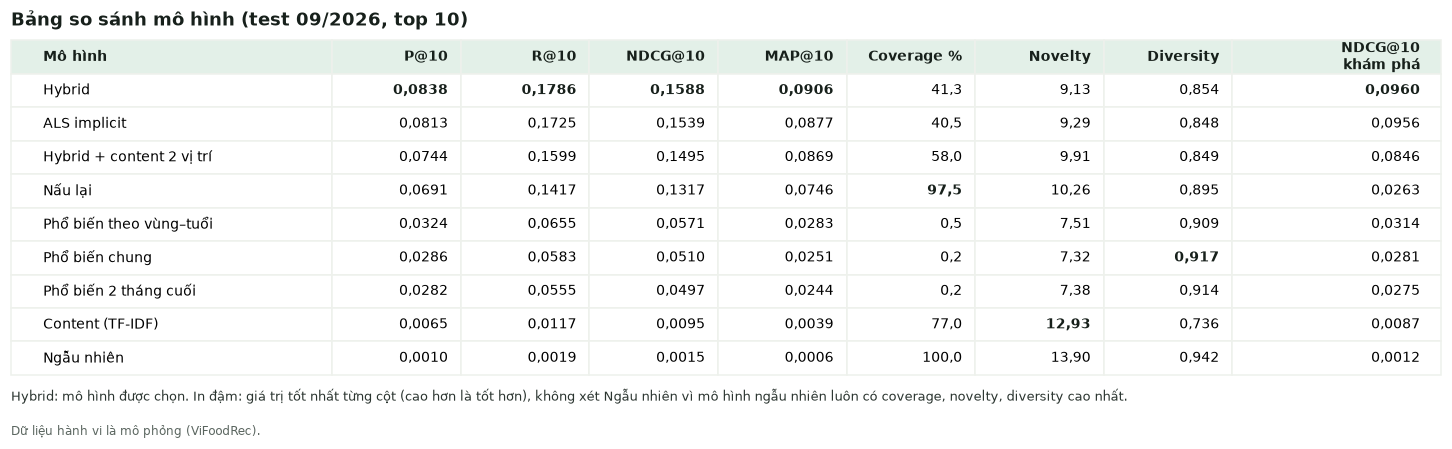

In [4]:
# Bang so sanh dang anh (dung truc tiep trong bao cao)
show = tbl.copy()
for c in ["P@10", "R@10", "NDCG@10", "MAP@10", "NDCG@10 khám phá"]:
    show[c] = show[c].map(lambda v: fmt(v, 4))
show["Coverage %"] = show["Coverage %"].map(lambda v: fmt(v, 1))
show["Novelty"] = show["Novelty"].map(lambda v: fmt(v, 2))
show["Diversity"] = show["Diversity"].map(lambda v: fmt(v, 3))
# In dam gia tri tot nhat tung cot (moi do do deu la cao hon tot hon). Ngau nhien chi la moc duoi: no luon
# co coverage / novelty / diversity cao nhat nen khong xet khi tim gia tri tot nhat.
num_cols = [c for c in tbl.columns if c != "Mô hình"]
cand = tbl[tbl["Mô hình"] != "Ngẫu nhiên"]
best = {c: cand[c].max() for c in num_cols}
fig = plt.figure(figsize=(13, 0.3 * (len(show) + 1) + 0.9))
ax = fig.add_axes([0, 0.12, 1, 0.78])          # bang sat le trai cua anh
ax.axis("off")
tb = ax.table(cellText=show.values, colLabels=[c.replace("@10 khám", "@10\nkhám") for c in show.columns], cellLoc="right",
              colLoc="right", colWidths=[0.2] + [0.08] * 7 + [0.13], bbox=[0, 0, 1, 1])
tb.auto_set_font_size(False); tb.set_fontsize(9)
cols = list(show.columns)
for (r, c), cell in tb.get_celld().items():
    cell.set_edgecolor(C["grid"])
    if c == 0:
        cell.set_text_props(ha="left"); cell._loc = "left"
    if r == 0:
        cell.set_text_props(weight="bold", color=C["ink"]); cell.set_facecolor(C["herb_soft"])
    elif c > 0 and tbl.iloc[r - 1][cols[c]] == best[cols[c]] and tbl.iloc[r - 1]["Mô hình"] != "Ngẫu nhiên":
        cell.set_text_props(weight="bold", color=C["ink"])
fig.text(0, 0.97, "Bảng so sánh mô hình (test 09/2026, top 10)", fontsize=12, fontweight="bold", color=C["ink"], va="top")
fig.text(0, 0.06, "Hybrid: mô hình được chọn. In đậm: giá trị tốt nhất từng cột (cao hơn là tốt hơn), không xét "
         "Ngẫu nhiên vì mô hình ngẫu nhiên luôn có coverage, novelty, diversity cao nhất.", fontsize=8.5, color=C["ink2"])
fig.text(0, -0.02, "Dữ liệu hành vi là mô phỏng (ViFoodRec).", fontsize=8, color=C["muted"])
save(fig, "06_bang_so_sanh", note=None)

## 2. Theo nhóm user: ấm / ít lịch sử / lạnh
Nhóm tính theo train + val: lạnh 1.291 user, ít 742, ấm 36.979. User lạnh không có lịch sử nên ALS không gợi ý được (NDCG = 0);
hybrid dùng phổ biến theo vùng–tuổi cho nhóm này.

da ghi docs/images/nb_06_ndcg_nhom_user.png


group,tất cả,ấm,ít,lạnh
model,,,,
hybrid,0.1588,0.1636,0.1034,0.0540
als_implicit,0.1539,0.1602,0.1062,0.0000
nau_lai,0.1317,0.1362,0.0588,0.0473
pop_vung_tuoi,0.0571,0.0573,0.0507,0.0540


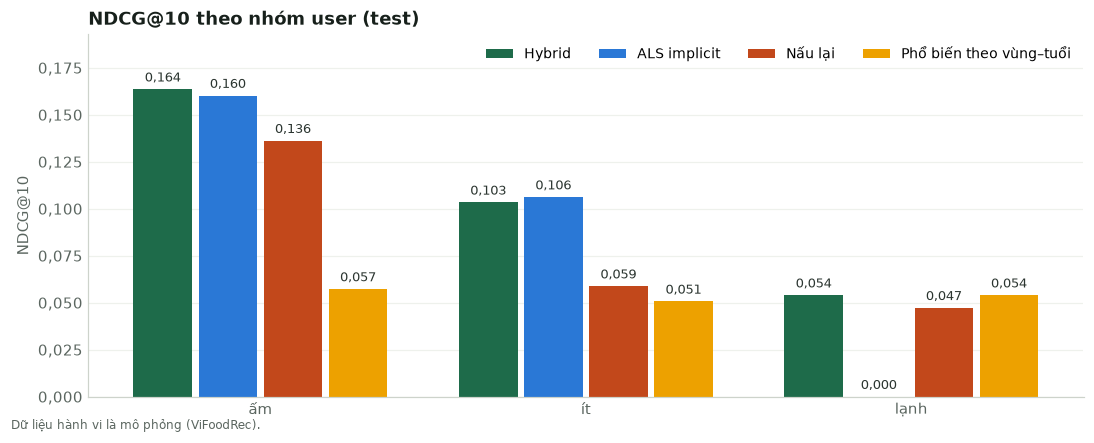

In [5]:
models = ["hybrid", "als_implicit", "nau_lai", "pop_vung_tuoi"]
groups = ["ấm", "ít", "lạnh"]
G = R[(R.view == "test") & (R.variant == "chính") & R.model.isin(models)].pivot(index="model", columns="group", values="ndcg@10")
fig, ax = plt.subplots(figsize=(10, 4))
w = 0.2
x = np.arange(len(groups))
for i, m in enumerate(models):
    b = ax.bar(x + (i - 1.5) * w, G.loc[m, groups], width=w - 0.02, color=SERIES[i], label=NAME[m])
    bar_labels(ax, b, nd=3)
ax.set_xticks(x, [f"{g}" for g in groups])
ax.set_ylabel("NDCG@10"); ax.set_ylim(0, G.loc[models, groups].values.max() * 1.18)
ax.legend(ncol=4, loc="upper right")
ax.set_title("NDCG@10 theo nhóm user (test)")
fig.tight_layout()
save(fig, "06_ndcg_nhom_user")
G.loc[models, ["tất cả"] + groups].round(4)

## 3. Khoảng tin cậy 95% của hiệu NDCG@10 (bootstrap theo user)
Khoảng không chứa 0 thì hiệu có ý nghĩa. Hybrid hơn ALS 0,0049 với khoảng [0,0042; 0,0056].

da ghi docs/images/nb_06_khoang_tin_cay.png


,label,hieu,lo,hi,n_users
10,Hybrid + content 2 vị trí − Hybrid,-0.0092,-0.0096,-0.0089,39012
0,Hybrid − ALS implicit,0.0049,0.0042,0.0056,39012
12,ALS implicit − Nấu lại,0.0221,0.0203,0.0240,39012
4,Hybrid − Nấu lại,0.0270,0.0254,0.0287,39012
6,Hybrid − Phổ biến theo vùng–tuổi,0.1017,0.0999,0.1035,39012
8,Hybrid − Phổ biến 2 tháng cuối,0.1091,0.1072,0.1110,39012
2,Hybrid − Content (TF-IDF),0.1493,0.1473,0.1514,39012


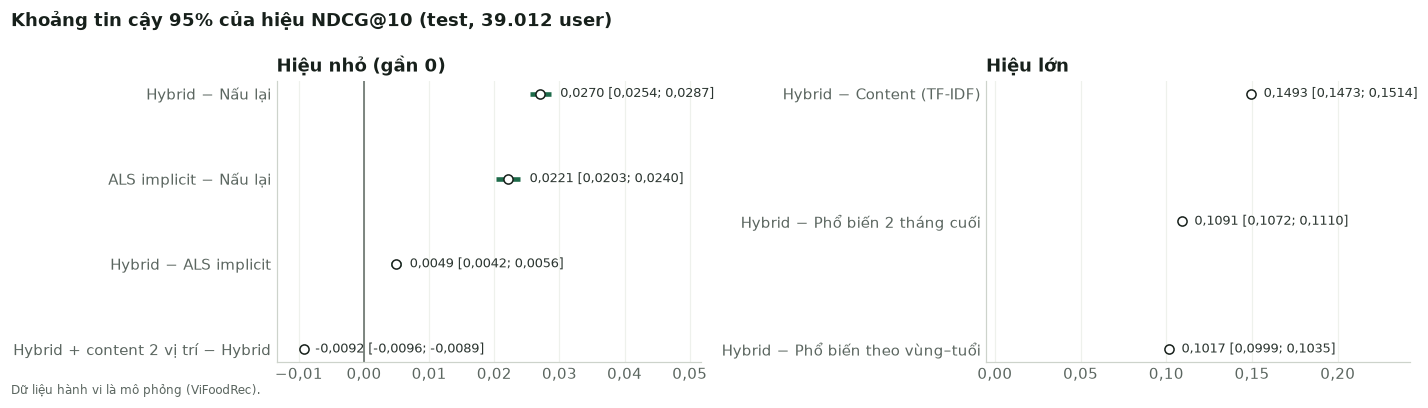

In [6]:
ci = pd.DataFrame(mm["ci95_test_ndcg@10"])
ci = ci[ci.users == "tất cả"].copy()
def nice(s):
    a, b = [p.strip() for p in s.split(" - ")]
    return f"{NAME.get(a, a)} − {NAME.get(b, b)}"
ci["label"] = ci.so_sanh.map(nice)
ci["lo"], ci["hi"] = ci.ci95.str[0], ci.ci95.str[1]
ci = ci.sort_values("hieu")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 1]})
small = ci[ci.hieu.abs() < 0.05]
big = ci[ci.hieu.abs() >= 0.05]
for ax, d, title in ((a1, small, "Hiệu nhỏ (gần 0)"), (a2, big, "Hiệu lớn")):
    y = np.arange(len(d))
    col = [C["chili"] if v < 0 else C["herb"] for v in d.hieu]
    ax.hlines(y, d.lo, d.hi, color=col, lw=3)
    ax.plot(d.hieu, y, "o", color="white", mec=C["ink"], ms=6)
    for yy, r in zip(y, d.itertuples()):
        ax.annotate(f"{fmt(r.hieu, 4)} [{fmt(r.lo, 4)}; {fmt(r.hi, 4)}]", (r.hi, yy), xytext=(6, 0),
                    textcoords="offset points", va="center", fontsize=8.5, color=C["ink2"])
    ax.set_yticks(y, d.label)
    if d.lo.min() < 0 < d.hi.max() or ax is a1:
        ax.axvline(0, color=C["muted"], lw=1)
    lo, hi = d.lo.min(), d.hi.max()
    ax.set_xlim(min(lo, 0) - (hi - lo) * 0.1, hi + (hi - min(lo, 0)) * 0.6)
    ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
    ax.set_title(title)
fig.suptitle("Khoảng tin cậy 95% của hiệu NDCG@10 (test, 39.012 user)", x=0.01, ha="left", fontweight="bold",
             color=C["ink"], fontsize=12)
fig.tight_layout()
save(fig, "06_khoang_tin_cay")
ci[["label", "hieu", "lo", "hi", "n_users"]]

## 4. Dò tham số ALS
**Implicit** (val, 10.000 user dò): alpha với rank 32, rồi mở rộng rank ở alpha tốt nhất (D13). Chọn alpha 1, rank 128.
**Explicit** (RMSE trên val): lưới rank × regParam.

da ghi docs/images/nb_06_luoi_als.png
trong so implicit (rank 128): {'1/3/5': 0.1623, '1/2/10': 0.162, 'chỉ cook': 0.1328}


,alpha,rank,regParam,weights,ndcg@10,p@10,r@10
0,0.25,32,0.1,1/3/5,0.1433,0.0781,0.1591
1,0.50,32,0.1,1/3/5,0.1485,0.0802,0.1636
2,1.00,32,0.1,1/3/5,0.1541,0.0835,0.1696
3,5.00,32,0.1,1/3/5,0.1506,0.0820,0.1707
4,20.00,32,0.1,1/3/5,0.1118,0.0607,0.1343
5,40.00,32,0.1,1/3/5,0.0808,0.0452,0.1048
6,1.00,64,0.1,1/3/5,0.1591,0.0856,0.1746
7,1.00,128,0.1,1/3/5,0.1623,0.0874,0.1797
8,1.00,128,0.1,1/2/10,0.1620,0.0874,0.1795
9,1.00,128,0.1,chỉ cook,0.1328,0.0736,0.1416


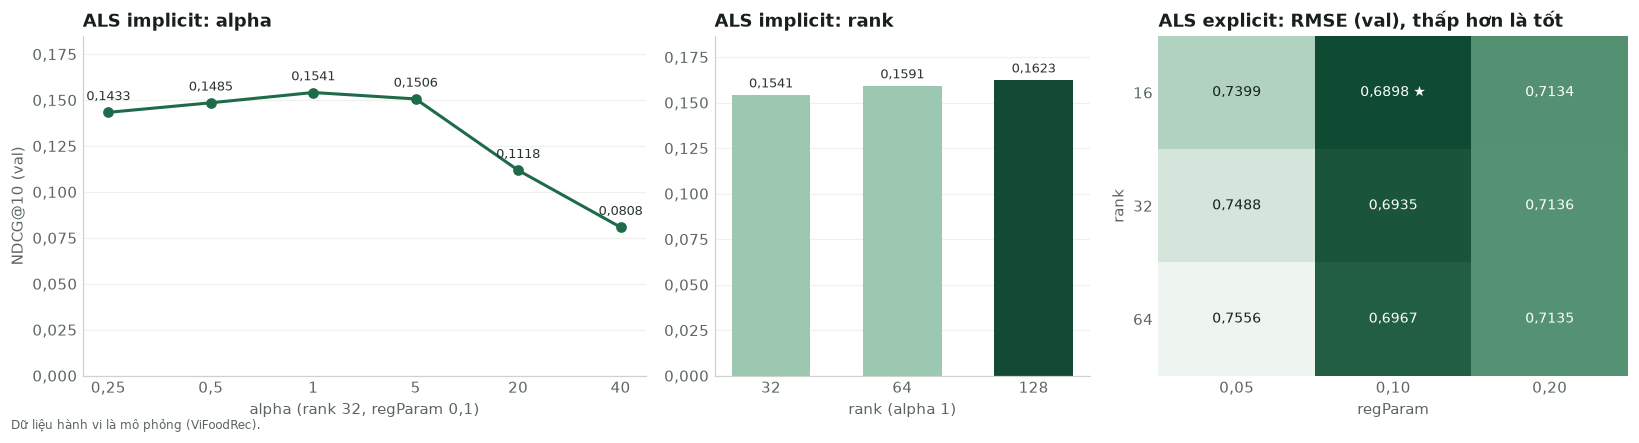

In [7]:
ti = pd.DataFrame(als["tuning_als_implicit"])
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={"width_ratios": [1.2, 0.8, 1]})
d = ti[(ti["rank"] == 32) & (ti.weights == "1/3/5")].sort_values("alpha")
alab = [fmt(a, 2).rstrip("0").rstrip(",") for a in d.alpha]
a1.plot(alab, d["ndcg@10"], marker="o", color=C["herb"])
for x, y in zip(alab, d["ndcg@10"]):
    a1.annotate(fmt(y, 4), (x, y), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8.5, color=C["ink2"])
a1.set_xlabel("alpha (rank 32, regParam 0,1)"); a1.set_ylabel("NDCG@10 (val)"); a1.set_ylim(0, d["ndcg@10"].max() * 1.2)
a1.set_title("ALS implicit: alpha")
d = ti[(ti.alpha == 1) & (ti.weights == "1/3/5")].sort_values("rank")
b = a2.bar([str(r) for r in d["rank"]], d["ndcg@10"], color=[C["herb_dark"] if r == 128 else C["herb_mid"] for r in d["rank"]], width=0.6)
bar_labels(a2, b, nd=4)
a2.set_ylim(0, d["ndcg@10"].max() * 1.15)
a2.set_xlabel("rank (alpha 1)"); a2.set_title("ALS implicit: rank")
te = pd.DataFrame(als["tuning_als_explicit"])
M = te.pivot(index="rank", columns="regParam", values="rmse")
im = a3.imshow(M.values, cmap=SEQ.reversed(), aspect="auto")
a3.set_xticks(range(len(M.columns)), [fmt(c, 2) for c in M.columns]); a3.set_yticks(range(len(M.index)), M.index)
a3.set_xlabel("regParam"); a3.set_ylabel("rank"); a3.grid(False)
best = M.stack().idxmin()
for i, r in enumerate(M.index):
    for j, c in enumerate(M.columns):
        v = M.loc[r, c]
        a3.text(j, i, fmt(v, 4) + (" ★" if (r, c) == best else ""), ha="center", va="center", fontsize=9,
                color="white" if v < M.values.min() + (M.values.max() - M.values.min()) * 0.4 else C["ink"])
a3.set_title("ALS explicit: RMSE (val), thấp hơn là tốt")
for s in a3.spines.values():
    s.set_visible(False)
fig.tight_layout()
save(fig, "06_luoi_als")
print("trong so implicit (rank 128):", als["sensitivity_implicit_weights_ndcg@10"])
ti

## 5. RMSE: dữ liệu mô phỏng so với ratings gốc (đối chứng 06g)
Trên ratings gốc (182.556 dòng, 101 user), ALS **kém** trung bình chung 6,0%; trên dữ liệu mô phỏng ALS tốt hơn 36,1%.
Vì vậy đánh giá chính dùng dữ liệu mô phỏng, còn ratings gốc chỉ làm đối chứng.

da ghi docs/images/nb_06_rmse_doi_chung.png


'/home/jovyan/work/docs/images/nb_06_rmse_doi_chung.png'

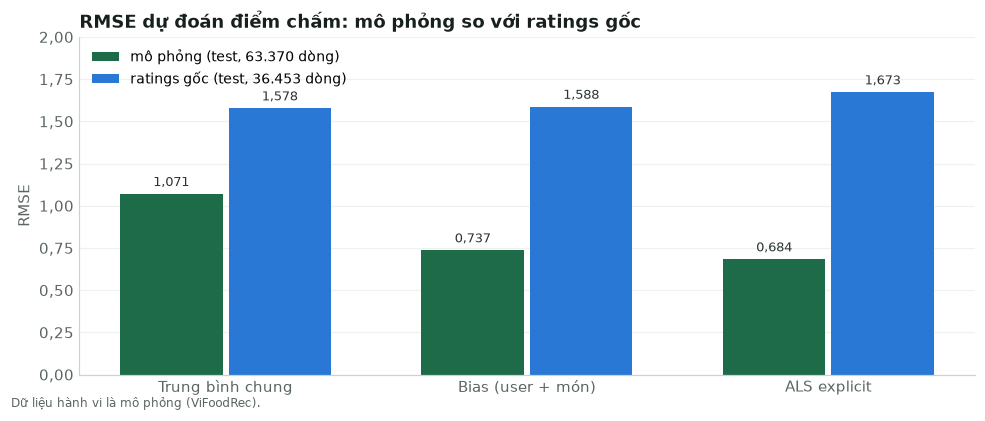

In [8]:
sim = als["test"]["rating"]["on_common_rows"]
org = ctl["test_common_rows"]
rows = [("Trung bình chung", sim["trung_binh"]["rmse"], org["trung_binh"]["rmse"]),
        ("Bias (user + món)", sim["bias"]["rmse"], org["bias"]["rmse"]),
        ("ALS explicit", sim["als_explicit"]["rmse"], org["als_explicit"]["rmse"])]
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(rows)); w = 0.36
b1 = ax.bar(x - w / 2, [r[1] for r in rows], width=w - 0.02, color=SERIES[0], label="mô phỏng (test, 63.370 dòng)")
b2 = ax.bar(x + w / 2, [r[2] for r in rows], width=w - 0.02, color=SERIES[1], label="ratings gốc (test, 36.453 dòng)")
bar_labels(ax, b1, nd=3); bar_labels(ax, b2, nd=3)
ax.set_xticks(x, [r[0] for r in rows]); ax.set_ylabel("RMSE"); ax.set_ylim(0, 2)
ax.legend(loc="upper left")
ax.set_title("RMSE dự đoán điểm chấm: mô phỏng so với ratings gốc")
fig.tight_layout()
save(fig, "06_rmse_doi_chung")

## 6. K-means phân khúc user: Silhouette, ARI, NMI theo k
ARI / NMI so cụm với persona ẩn của bộ sinh (`users_truth`) — chỉ có được vì dữ liệu là mô phỏng.
Silhouette cao nhất ở k = 3; dashboard dùng k = 8 (ARI cao hơn, cụm dễ đặt tên hơn).

da ghi docs/images/nb_06_kmeans_theo_k.png


silhouette                    ari                    nmi       
algo BisectingKMeans KMeans BisectingKMeans KMeans BisectingKMeans KMeans
k                                                                        
2              0.207  0.207           0.151  0.151           0.238  0.238
3              0.211  0.227           0.236  0.284           0.330  0.365
4              0.191  0.199           0.333  0.392           0.385  0.417
5              0.150  0.165           0.402  0.434           0.436  0.454
6              0.143  0.174           0.407  0.463           0.436  0.479
7              0.131  0.168           0.382  0.444           0.428  0.467
8              0.144  0.174           0.377  0.418           0.421  0.442
9              0.125  0.183           0.389  0.451           0.416  0.472
10             0.118  0.178           0.350  0.469           0.408  0.484
11             0.074  0.184           0.313  0.503           0.405  0.512
12             0.064  0.169           0.310  0.446           0.398  0.500

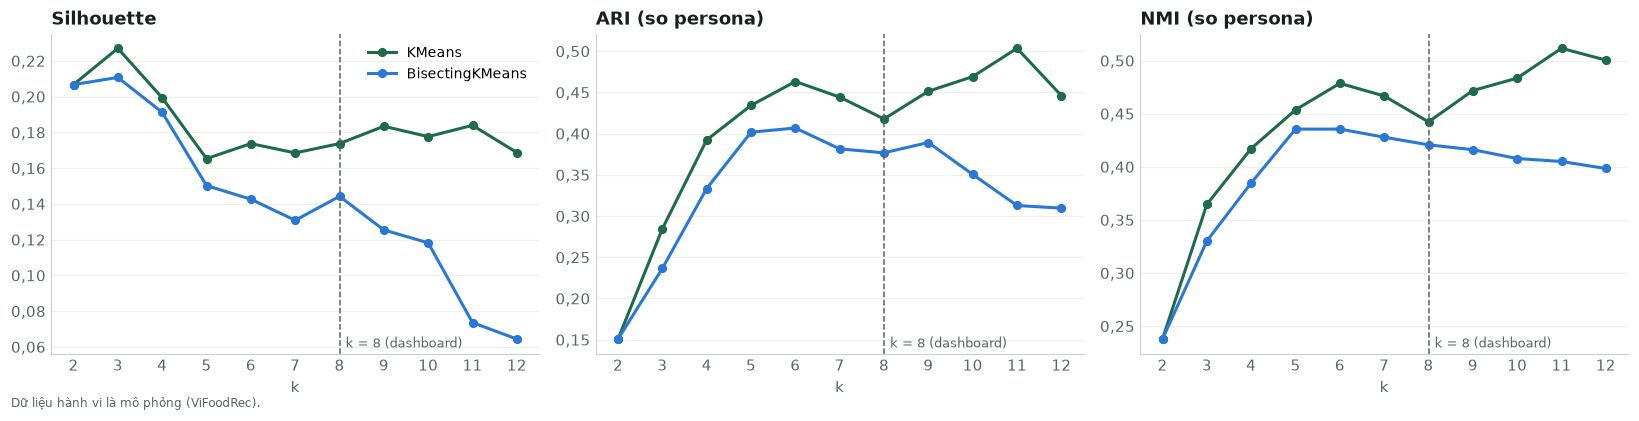

In [9]:
ks = pd.DataFrame(km["search"])
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), sharex=True)
for ax, met, title in zip(axs, ["silhouette", "ari", "nmi"], ["Silhouette", "ARI (so persona)", "NMI (so persona)"]):
    for i, algo in enumerate(["KMeans", "BisectingKMeans"]):
        d = ks[ks.algo == algo].sort_values("k")
        ax.plot(d.k, d[met], marker="o", ms=5, color=SERIES[i], label=algo)
    ax.axvline(8, color=C["muted"], lw=1, ls="--")
    ax.annotate("k = 8 (dashboard)", (8, ax.get_ylim()[0]), xytext=(4, 4), textcoords="offset points", fontsize=8.5,
                color=C["muted"])
    ax.set_xlabel("k"); ax.set_title(title)
    ax.set_xticks(range(2, 13))
axs[0].legend(loc="upper right")
fig.tight_layout()
save(fig, "06_kmeans_theo_k")
ks.pivot(index="k", columns="algo", values=["silhouette", "ari", "nmi"]).round(3)

## 7. Content: MinHashLSH so với tính chính xác
Tính chính xác 10,9 triệu cặp món có độ tương đồng khác 0 mất khoảng 37 giây. LSH tìm ứng viên nhanh hơn
nhưng bỏ sót; recall@20 = tỷ lệ 20 món giống nhất (chính xác) có trong ứng viên của LSH.

da ghi docs/images/nb_06_lsh_recall.png


,numHashTables,candidate_pairs,recall@20,seconds
0,3,2520404,0.7886,14.0
1,5,2885456,0.8681,16.6
2,10,4991974,0.9927,36.2


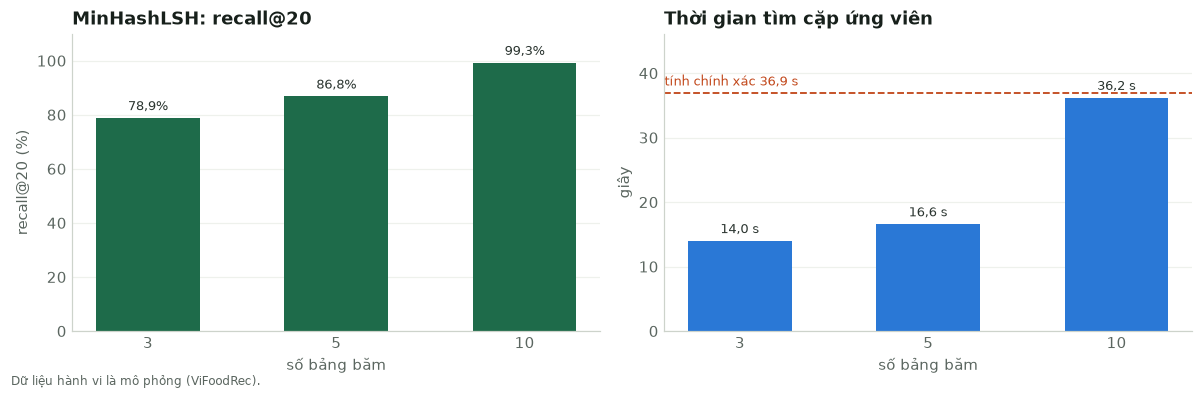

In [10]:
lsh = pd.DataFrame(cont["minhash"])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
b = a1.bar([str(n) for n in lsh.numHashTables], lsh["recall@20"] * 100, color=C["herb"], width=0.55)
bar_labels(a1, b, nd=1, suffix="%")
a1.set_ylim(0, 110); a1.set_xlabel("số bảng băm"); a1.set_ylabel("recall@20 (%)"); a1.set_title("MinHashLSH: recall@20")
b = a2.bar([str(n) for n in lsh.numHashTables], lsh.seconds, color=C["blue"], width=0.55)
bar_labels(a2, b, nd=1, suffix=" s")
a2.axhline(cont["exact_seconds"], color=C["chili"], lw=1.2, ls="--")
a2.annotate(f"tính chính xác {fmt(cont['exact_seconds'], 1)} s", (-0.4, cont["exact_seconds"]), xytext=(0, 5),
            textcoords="offset points", fontsize=8.5, color=C["chili"])
a2.set_ylim(0, max(lsh.seconds.max(), cont["exact_seconds"]) * 1.25)
a2.set_xlabel("số bảng băm"); a2.set_ylabel("giây"); a2.set_title("Thời gian tìm cặp ứng viên")
fig.tight_layout()
save(fig, "06_lsh_recall")
lsh

## 8. Hybrid: trọng số, món mới (cold item), FP-Growth

da ghi docs/images/nb_06_mon_moi_fpgrowth.png


,w,ndcg@10
0,"{'als': 0.9, 'content': 0.0, 'pop': 0.0, 'rep'...",0.1728
1,"{'als': 0.8, 'content': 0.0, 'pop': 0.0, 'rep'...",0.1718
2,"{'als': 0.7, 'content': 0.0, 'pop': 0.0, 'rep'...",0.1701
3,"{'als': 0.8, 'content': 0.1, 'pop': 0.0, 'rep'...",0.1692
4,"{'als': 1.0, 'content': 0.0, 'pop': 0.0, 'rep'...",0.1691


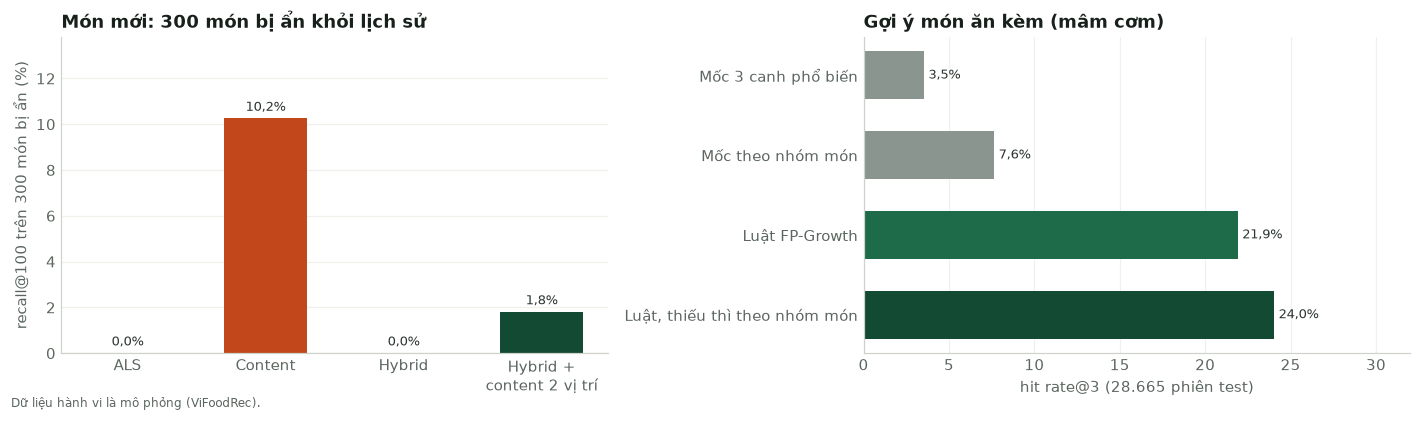

In [11]:
ci_items = hyb["cold_items"]
src = ["als", "content", "hybrid", "hybrid_c2"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.8))
vals = [ci_items["by_source"][s]["hidden_recall@100"] * 100 for s in src]
b = a1.bar(["ALS", "Content", "Hybrid", "Hybrid +\ncontent 2 vị trí"], vals,
           color=[C["neutral"], C["chili"], C["herb"], C["herb_dark"]], width=0.6)
bar_labels(a1, b, nd=1, suffix="%")
a1.set_ylabel("recall@100 trên 300 món bị ẩn (%)"); a1.set_ylim(0, max(vals) * 1.25 + 1)
a1.set_title(f"Món mới: {ci_items['hidden_items']} món bị ẩn khỏi lịch sử")
ev = fp["meal_eval_hit_rate@3"]
names = ["Mốc 3 canh phổ biến", "Mốc theo nhóm món", "Luật FP-Growth", "Luật, thiếu thì theo nhóm món"]
keys = ["moc_3_canh_pho_bien", "moc_theo_nhom_mon", "luat_fpgrowth", "luat_fpgrowth_thieu_thi_theo_nhom_mon"]
b = a2.barh(names[::-1], [ev[k] * 100 for k in keys][::-1], color=[C["neutral"], C["neutral"], C["herb"], C["herb_dark"]][::-1],
            height=0.6)
bar_labels(a2, b, nd=1, suffix="%", horizontal=True)
a2.set_xlim(0, 32); a2.grid(axis="y", visible=False); a2.grid(axis="x", visible=True)
a2.set_xlabel(f"hit rate@3 ({fmt(ev['test_sessions'])} phiên test)"); a2.set_title("Gợi ý món ăn kèm (mâm cơm)")
fig.tight_layout()
save(fig, "06_mon_moi_fpgrowth")
pd.DataFrame(hyb["tuning"]["top5"]).assign(w=lambda d: d.w.astype(str))